# 1.3 Statistical Hypothesis Testing

## 1. Introduction

This phase will examine two associations relevant to predicting `Failure`:
service hours and failure status, and missing filter pressure measurements
and failure status. Requirement 1.3(A) calls for two hypotheses and appropriate
tests; 1.3(B) calls for an assessment of statistical power.

This notebook implements preparation, the two hypothesis tests and simulation-based
statistical power and sensitivity analyses. Associations will not establish causation
or demonstrate advance prediction. Phase 1.1 motivated these topics, so the
p-values should be interpreted as exploratory rather than independent confirmation.

Local sources reviewed: `../IAU-zadanie.pdf` (Phase 1, section 1.3),
`phase1.1_eda.ipynb` and `phase1.2_cleaning.ipynb`. The assignment requires
exactly two research hypotheses with appropriate tests (4 points) and an
assessment of statistical power (1 point). It also requires saved results,
interpretations and each team member's contribution percentage. Relevant IAU
seminar notebooks are not available locally, so no direct seminar comparison
or seminar-specific method claim is made.

## 2. Dataset Preparation

### Reusing Phase 1.2

Run the existing Phase 1.2 preparation code in an isolated namespace through
its first data consistency check (before Device–Gateway Consistency).
This reuses loading, exact duplicate removal, validated identifier normalization,
explicit date parsing and ambiguity flags, missingness flags, the invalid oil
measurement rule, and the many-to-one LEFT JOIN. Only source code is read;
Phases 1.1 and 1.2 are not modified and saved outputs are not used as data.

The working dataset is `integrated`, equivalent to the baseline retained in
Phase 1.2. Experimental IQR removal and percentile clipping are not applied.
No imputation, relabelling or additional outlier treatment is introduced.
Gateway metadata is not included. Original identifiers, labels and timestamps
are retained; unresolved dates and unmatched metadata remain flagged.

Run from the repository root or `notebooks/`. This notebook requires the same
Python environment as Phase 1.2 plus `nbformat`, SciPy and a Jupyter kernel.

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO
import nbformat
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
CLEANING_NOTEBOOK = ROOT / "notebooks" / "phase1.2_cleaning.ipynb"
assert CLEANING_NOTEBOOK.is_file() and (ROOT / "data").is_dir()

cleaning_notebook = nbformat.read(CLEANING_NOTEBOOK, as_version=4)
# Use a named section boundary rather than fragile cell numbers.
boundaries = [
    i for i, cell in enumerate(cleaning_notebook.cells)
    if cell.cell_type == "markdown"
    and cell.source.strip().startswith("### Device–Gateway Consistency")
]
assert len(boundaries) == 1, "Review the Phase 1.2 preparation boundary."
preparation_namespace = {"__name__": "phase12_preparation"}
executed_cells = []
with redirect_stdout(StringIO()):
    for i, cell in enumerate(cleaning_notebook.cells[:boundaries[0]]):
        if cell.cell_type == "code":
            # Suppress repeated display tables after the imports in each cell.
            source = cell.source.replace(
                "from IPython.display import display",
                "from IPython.display import display as _source_display",
            )
            preparation_namespace["display"] = lambda *args, **kwargs: None
            exec(compile(source, f"{CLEANING_NOTEBOOK.name}:cell-{i + 1}", "exec"),
                 preparation_namespace)
            executed_cells.append(i + 1)

prepared = preparation_namespace["integrated"].copy()
readings_clean = preparation_namespace["readings"]
units_clean = preparation_namespace["units"]
readings_raw = preparation_namespace["readings_raw"]
print("Reused Phase 1.2 code cells (1-based):", executed_cells)
print(f"Exact duplicates removed: {len(readings_raw) - len(readings_clean):,}")
print(f"Prepared readings: {len(prepared):,}")

Reused Phase 1.2 code cells (1-based): [2, 4, 6, 8, 10, 12, 14, 16, 18, 21]
Exact duplicates removed: 196
Prepared readings: 13,092


### Join and label validation

Phase 1.2 checks the full `U[0-9]+` reading-ID format before extracting
the numeric key and rejects collisions. For example, `U00596` maps to 596.
Units must have complete, unique numeric keys. The LEFT JOIN retains readings
without unit metadata and enforces a many-to-one relationship.
The checks below independently compare joined service hours with a key lookup,
and compare every retained Failure label and filterDp value with its source row.

In [2]:
assert units_clean["unit_key"].notna().all() and units_clean["unit_key"].is_unique
assert len(prepared) == len(readings_clean)
assert prepared["reading_row_id"].is_unique
assert set(prepared["reading_row_id"]) == set(readings_clean.index)
assert prepared["Failure"].isin([0, 1]).all(), "Review missing or invalid labels."
by_source = prepared.set_index("reading_row_id").sort_index()
for column in ["unitId", "unit_key", "Failure", "filterDp"]:
    pd.testing.assert_series_equal(by_source[column], readings_clean[column].sort_index().rename_axis("reading_row_id"))
expected_hours = prepared["unit_key"].map(units_clean.set_index("unit_key")["serviceHours"])
pd.testing.assert_series_equal(prepared["serviceHours"], expected_hours, check_names=False)
assert np.array_equal(
    prepared["device_match"].eq("left_only"),
    ~prepared["unit_key"].isin(units_clean["unit_key"]),
)
assert np.isfinite(prepared["serviceHours"].dropna()).all()
assert prepared["serviceHours"].dropna().ge(0).all()
assert np.isfinite(prepared["filterDp"].dropna()).all()

required_columns = ["Failure", "serviceHours", "filterDp", "unitId"]
display(pd.DataFrame({
    "missing_count": prepared[required_columns].isna().sum(),
    "missing_percent": prepared[required_columns].isna().mean().mul(100),
}).round(2))
display(prepared.groupby("Failure", dropna=False).agg(
    rows=("Failure", "size"), unique_units=("unit_key", "nunique"),
    unmatched_readings=("device_match", lambda x: x.eq("left_only").sum()),
    missing_serviceHours=("serviceHours", lambda x: x.isna().sum()),
    missing_filterDp=("filterDp", lambda x: x.isna().sum()),
).assign(percent=lambda x: 100 * x["rows"] / len(prepared)).round(2))
print("Unique units:", prepared["unit_key"].nunique())
print("Unmatched units:", prepared.loc[prepared["device_match"].eq("left_only"), "unit_key"].nunique())
print("Missing serviceHours among matched readings:",
      prepared.loc[prepared["device_match"].eq("both"), "serviceHours"].isna().sum())
print("Join, source-value and label checks passed.")

,missing_count,missing_percent
Failure,0,0.00
serviceHours,743,5.68
filterDp,531,4.06
unitId,0,0.00


,rows,unique_units,unmatched_readings,missing_serviceHours,missing_filterDp,percent
Failure,,,,,,
0,11498,2104,117,650,236,87.82
1,1594,1030,14,93,295,12.18


Unique units: 2117
Unmatched units: 119
Missing serviceHours among matched readings: 612
Join, source-value and label checks passed.


### Repeated measurements and changing labels

Count readings and distinct labels per unit before choosing the analysis unit.
Units with both labels contribute to both row-level classes; the unique-unit
counts by Failure therefore overlap. Label variation within a unit does not
by itself establish a temporal transition. We also inspect resolved timestamps,
report ties with conflicting labels, and count adjacent label changes only
between timestamps with a single observed label. Ambiguous dates are excluded
from this temporal diagnostic, not from the prepared dataset. Date-only records
cannot establish the order of measurements within a day.

,readings_per_unit
count,2117.00
mean,6.18
std,2.75
min,1.00
25%,4.00
50%,6.00
75%,8.00
max,18.00


,units
label_pattern,
Only Failure = 0,1087
Both labels,1017
Only Failure = 1,13


,readings
ts_cycle_status,
parsed,11958
ambiguous,1134


,count
units_with_both_labels_all_readings,1017
units_with_both_labels_resolved_dates,956
unit_timestamp_groups_with_both_labels,13
units_with_ordered_label_changes,950
adjacent_changes_at_resolved_nonconflicting_times,1980
readings_with_explicit_time,3193


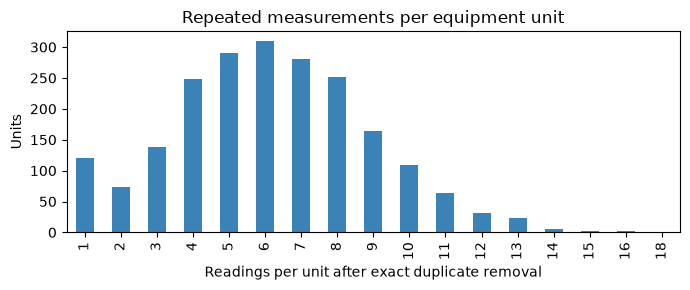

In [3]:
unit_summary = prepared.groupby("unit_key").agg(
    unitId=("unitId", "first"), readings=("Failure", "size"),
    failure_labels=("Failure", "nunique"), failure_min=("Failure", "min"),
    failure_max=("Failure", "max"),
)
unit_summary["label_pattern"] = np.select(
    [unit_summary["failure_labels"].eq(2), unit_summary["failure_max"].eq(0)],
    ["Both labels", "Only Failure = 0"], default="Only Failure = 1",
)
display(unit_summary["readings"].describe().to_frame("readings_per_unit").round(2))
display(unit_summary["label_pattern"].value_counts().to_frame("units"))
display(prepared["ts_cycle_status"].value_counts(dropna=False).to_frame("readings"))
resolved = prepared.loc[prepared["ts_cycle_parsed"].notna()]
at_time = resolved.groupby(["unit_key", "ts_cycle_parsed"]).agg(
    distinct_labels=("Failure", "nunique"), Failure=("Failure", "first"),
)
ordered = at_time.loc[at_time["distinct_labels"].eq(1)].reset_index().sort_values(
    ["unit_key", "ts_cycle_parsed"]
)
previous = ordered.groupby("unit_key")["Failure"].shift()
changed = previous.notna() & ordered["Failure"].ne(previous)
display(pd.Series({
    "units_with_both_labels_all_readings": unit_summary["failure_labels"].eq(2).sum(),
    "units_with_both_labels_resolved_dates": resolved.groupby("unit_key")["Failure"].nunique().eq(2).sum(),
    "unit_timestamp_groups_with_both_labels": at_time["distinct_labels"].eq(2).sum(),
    "units_with_ordered_label_changes": ordered.loc[changed, "unit_key"].nunique(),
    "adjacent_changes_at_resolved_nonconflicting_times": changed.sum(),
    "readings_with_explicit_time": prepared["ts_cycle_has_time"].sum(),
}).to_frame("count"))

fig, ax = plt.subplots(figsize=(7, 3))
unit_summary["readings"].value_counts().sort_index().plot.bar(ax=ax, color="#3B82B6")
ax.set_xlabel("Readings per unit after exact duplicate removal")
ax.set_ylabel("Units")
ax.set_title("Repeated measurements per equipment unit")
fig.tight_layout()
plt.show()

### Independent unit of analysis

Use **one randomly selected observed reading per unit**, with a fixed seed of
133 and stable sorting. Selection uses neither Failure nor measurement
availability: sample before excluding missing service hours, and keep a missing
filterDp value as an observed missingness outcome. The original label on the
selected row is preserved. Both analyses use the same selected rows.
We do not label a unit by whether it ever failed: that would change the outcome
to an observation-window event, favour units observed more often, and disconnect
filterDp missingness from the selected failure status.

The estimand concerns failure status at a randomly selected recorded occasion
for an equally weighted observed unit. It is not a failure incidence rate or a
future failure risk. Selecting a random recorded occasion is not sampling a
uniform point in calendar time, and observation schedules may be informative.

This design removes within-unit replication from conventional independent-sample
tests, assuming different units are independent. Shared depots, environments or
maintenance may still create dependence; this assumption is not established by
unique IDs. A later cluster-aware analysis could retain all readings, but ordinary
row-level tests must not be applied to that full table.

The price is loss of repeated-measurement information, temporal ordering,
within-unit changes and statistical power. Seed 133 is fixed before testing;
do not try seeds to obtain significance. No averaging or majority/ever-failure
aggregation is applied. Dates are not used to select a first or last record,
because unresolved dates and incomplete time precision make that choice unreliable.
Static serviceHours may not represent hours accumulated at the selected occasion;
its timing must be verified before making predictive claims.

In [4]:
RANDOM_SEED = 133
analysis_units = (
    prepared.sort_values(["unit_key", "reading_row_id"])
    .groupby("unit_key", group_keys=False).sample(n=1, random_state=RANDOM_SEED)
    .sort_values("unit_key").reset_index(drop=True)
)
assert analysis_units["unit_key"].is_unique
assert len(analysis_units) == prepared["unit_key"].nunique()
assert set(analysis_units["unit_key"]) == set(prepared["unit_key"])
# Confirm that each selected row, including its label, is unchanged.
pd.testing.assert_frame_equal(
    analysis_units.set_index("reading_row_id").sort_index(),
    prepared.set_index("reading_row_id").loc[analysis_units["reading_row_id"]].sort_index(),
)

# Hypothesis-specific availability is applied only after the common sampling step.
h1_data = analysis_units.loc[analysis_units["serviceHours"].notna(),
    ["unitId", "unit_key", "reading_row_id", "Failure", "serviceHours"]].copy()
h2_data = analysis_units[["unitId", "unit_key", "reading_row_id", "Failure", "filterDp"]].copy()
h2_data["filterDp_missing"] = h2_data["filterDp"].isna()

sample_overview = []
for name, frame in [("Prepared readings (descriptive only)", prepared),
                    ("Selected units / H2", analysis_units),
                    ("H1: available serviceHours", h1_data)]:
    sample_overview.append({
        "sample": name, "rows": len(frame), "units": frame["unit_key"].nunique(),
        "Failure_0": frame["Failure"].eq(0).sum(),
        "Failure_1": frame["Failure"].eq(1).sum(),
        "Failure_1_percent": 100*frame["Failure"].eq(1).mean(),
    })
display(pd.DataFrame(sample_overview).set_index("sample").round(2))
print("Missingness in the selected-unit dataset:")
display(pd.DataFrame({
    "missing_count": analysis_units[required_columns].isna().sum(),
    "missing_percent": analysis_units[required_columns].isna().mean().mul(100),
}).round(2))
print("Selected-unit metadata and serviceHours availability by Failure:")
display(analysis_units.groupby("Failure").agg(
    units=("unit_key", "size"),
    unmatched=("device_match", lambda x: x.eq("left_only").sum()),
    missing_serviceHours=("serviceHours", lambda x: x.isna().sum()),
))
print("Rows excluded from H1 due to unavailable serviceHours:", len(analysis_units) - len(h1_data))


,rows,units,Failure_0,Failure_1,Failure_1_percent
sample,,,,,
Prepared readings (descriptive only),13092,2117,11498,1594,12.18
Selected units / H2,2117,2117,1844,273,12.90
H1: available serviceHours,1898,1898,1648,250,13.17


Missingness in the selected-unit dataset:


,missing_count,missing_percent
Failure,0,0.00
serviceHours,219,10.34
filterDp,91,4.30
unitId,0,0.00


Selected-unit metadata and serviceHours availability by Failure:


,units,unmatched,missing_serviceHours
Failure,,,
0,1844,108,196
1,273,11,23


Rows excluded from H1 due to unavailable serviceHours: 219


### Preparation findings and limitations

After Phase 1.2 duplicate removal, 13,092 readings remain across 2,117 units.
There are 11,498 non-failure and 1,594 failure readings (12.18% failure).
The validated join retains 131 unmatched readings. Among units, 1,087 have only
label 0, 13 have only label 1, and 1,017 have both labels. Thus repeated records
cannot be treated as independent or assigned one persistent observed Failure label.
Among resolved dates, 956 units have both labels. After excluding 13
unit-timestamp groups with conflicting labels, 950 units show an observed
label change between ordered timestamps. These are changes in recorded labels,
not verified physical failure/recovery events; incomplete time precision and
unresolved dates limit the chronology.

The fixed sampling strategy retains all 2,117 units: 1,844 selected labels are 0
and 273 are 1. In this selected dataset, 219 serviceHours values and 91 filterDp
values are missing. H1 has 1,898 available units (1,648 label 0; 250 label 1).
Its complete-case comparison is conditional on serviceHours availability and may
be biased if metadata missingness is informative. H2 retains all 2,117 units;
missing filterDp is the outcome being described, not a reason to exclude a unit.
Unmatched units remain in H2 and in the common selected table.

The following sections test associations on these prepared unit-level samples.
The power assessment in Section 5 uses the independent-unit sample sizes
and class imbalance, not the 13,092 correlated reading rows. Remaining date and
metadata-timing limitations from Phase 1.2 still apply.

## 3. Hypothesis 1 - Service Hours and Failure

**Research question:** Is equipment operating time associated with Failure?

For units with available serviceHours, let X1 and X0 denote service hours in
selected readings with Failure = 1 and 0, respectively.

- **H0:** The serviceHours distributions are identical in the two Failure groups.
- **H1:** The distributions differ (two-sided).

Use alpha = 0.05. This is a distributional comparison, not a hypothesis solely
about means or medians. We use the previously fixed one-reading-per-unit sample;
each unit occurs in only one group. Independence between different units remains
an assumption, as discussed in Section 2. The 219 units with unavailable serviceHours
are explicitly excluded only from this comparison. No outliers are removed.

Unavailable serviceHours excluded after unit sampling: 219


,count,mean,std,min,5%,25%,50%,75%,95%,max,skewness
Failure,,,,,,,,,,,
0,1648.0,13412.24,8328.54,1465.6,4441.94,7255.10,11297.60,16829.65,29791.34,45000.0,1.49
1,250.0,17687.39,10410.90,2936.7,6053.88,10066.65,14345.35,23020.40,43298.10,45000.0,1.15


IQR diagnostic only; flagged observations are retained:


,lower_fence,upper_fence,IQR_outliers,outlier_percent
Failure,,,,
0,-7106.72,31191.47,74,4.49
1,-9363.98,42451.03,14,5.60


Shapiro-Wilk normality diagnostic:


,n,Shapiro_W,p_value
Failure,,,
0,1648,0.873515,1.381956e-34
1,250,0.883687,6.519082e-13


Median-centered Levene test: W = 16.1635, p = 6.03776e-05


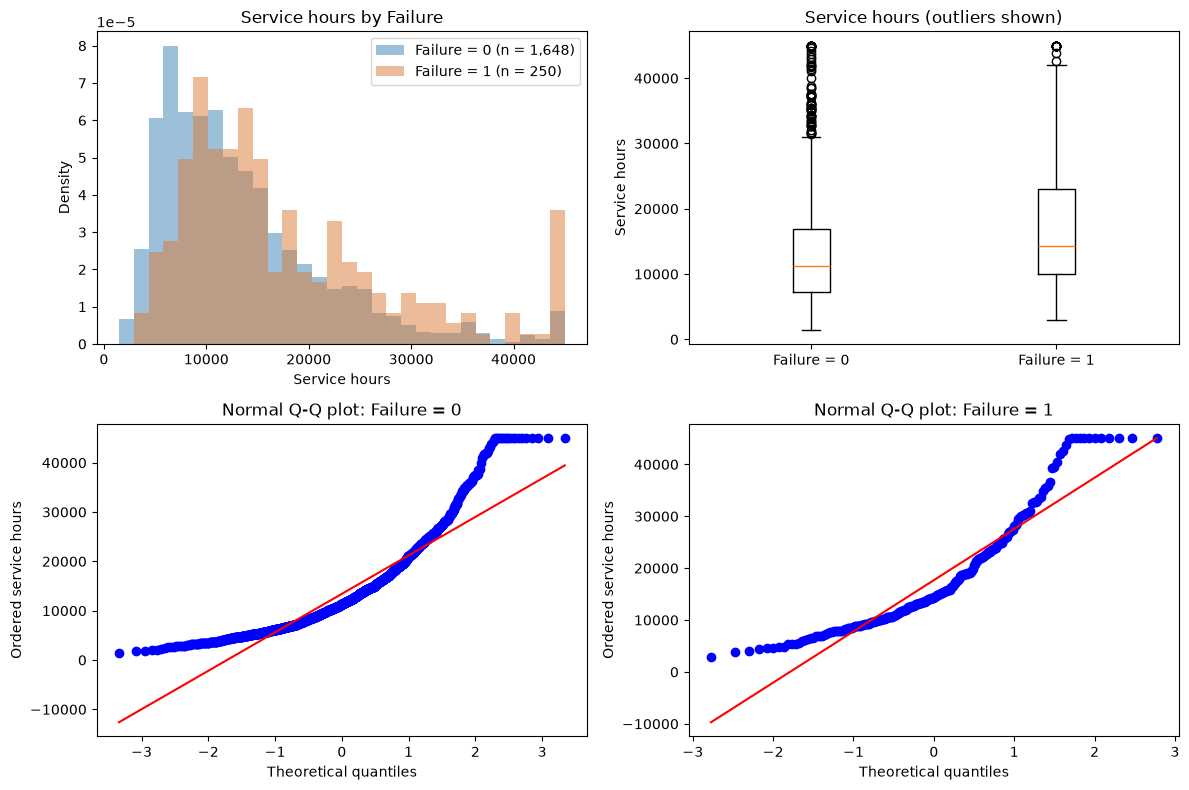

In [5]:
from scipy import stats
from IPython.display import Markdown

ALPHA = 0.05
assert h1_data["unit_key"].is_unique
assert h1_data["Failure"].isin([0, 1]).all()
assert h1_data["serviceHours"].notna().all()
assert np.isfinite(h1_data["serviceHours"]).all()
service_groups = {
    label: h1_data.loc[h1_data["Failure"].eq(label), "serviceHours"].to_numpy()
    for label in (0, 1)
}
print(f"Unavailable serviceHours excluded after unit sampling: {len(analysis_units) - len(h1_data)}")
service_summary = h1_data.groupby("Failure")["serviceHours"].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
)
service_summary["skewness"] = h1_data.groupby("Failure")["serviceHours"].skew()
display(service_summary.round(2))

# Describe IQR outliers without excluding them from the analysis.
outlier_rows = []
normality_rows = []
for label, values in service_groups.items():
    q1, q3 = np.quantile(values, [0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flagged = (values < lower) | (values > upper)
    outlier_rows.append({"Failure": label, "lower_fence": lower,
        "upper_fence": upper, "IQR_outliers": flagged.sum(),
        "outlier_percent": 100 * flagged.mean()})
    # Both groups have fewer than 5,000 observations, so use the full samples.
    result = stats.shapiro(values)
    normality_rows.append({"Failure": label, "n": len(values),
        "Shapiro_W": result.statistic, "p_value": result.pvalue})
print("IQR diagnostic only; flagged observations are retained:")
display(pd.DataFrame(outlier_rows).set_index("Failure").round(2))
print("Shapiro-Wilk normality diagnostic:")
display(pd.DataFrame(normality_rows).set_index("Failure"))
levene_result = stats.levene(service_groups[0], service_groups[1], center="median")
print(f"Median-centered Levene test: W = {levene_result.statistic:.4f}, "
      f"p = {levene_result.pvalue:.6g}")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
bins = np.histogram_bin_edges(h1_data["serviceHours"], bins=30)
for label, color in zip((0, 1), ("#3B82B6", "#D97936")):
    axes[0, 0].hist(service_groups[label], bins=bins, density=True, alpha=0.5,
                    color=color, label=f"Failure = {label} (n = {len(service_groups[label]):,})")
    stats.probplot(service_groups[label], dist="norm", plot=axes[1, label])
    axes[1, label].set_title(f"Normal Q-Q plot: Failure = {label}")
    axes[1, label].set_ylabel("Ordered service hours")
axes[0, 0].set(title="Service hours by Failure", xlabel="Service hours", ylabel="Density")
axes[0, 0].legend()
axes[0, 1].boxplot([service_groups[0], service_groups[1]], showfliers=True)
axes[0, 1].set_xticks([1, 2], labels=["Failure = 0", "Failure = 1"])
axes[0, 1].set(title="Service hours (outliers shown)", ylabel="Service hours")
fig.tight_layout()
plt.show()

### Assumptions and test choice

Both groups are right-skewed (sample skewness about 1.49 and 1.15 for Failure
0 and 1). The normal Q-Q plots depart from a straight line. Shapiro-Wilk rejects
normality in both groups, and median-centered Levene gives p = 0.0000604,
indicating unequal spread. These are diagnostics, not extra research hypotheses;
normality tests are sensitive at large sample sizes. IQR flags alone do not show
that measurements are errors.

Welch's t-test could target mean differences with sufficiently stable sample means
and does not require equal variances. Here we choose **Mann-Whitney U** for the
stated distributional question, to avoid making means and normal distributions
the focus for these skewed data. We use its two-sided large-sample approximation
with tie correction and continuity correction; both groups are sufficiently large.
We do not choose a test simply by whether it yields a smaller p-value.

Unequal spreads mean this must not be described as a pure shift or a test of median
differences. The test is sensitive to rank separation; it is not an omnibus test
that detects every possible difference in distributions. Its effect size is
A = P(X1 > X0) + 0.5 P(X1 = X0), estimated by U1 / (n1*n0).
A = 0.5 means no pairwise rank advantage. The rank-biserial effect 2A - 1 is
positive when service hours tend to be greater in Failure = 1. A separate
within-group bootstrap provides a descriptive 95% percentile interval for A.

In [6]:
x1, x0 = service_groups[1], service_groups[0]
h1_result = stats.mannwhitneyu(
    x1, x0, alternative="two-sided", method="asymptotic", use_continuity=True
)
superiority = h1_result.statistic / (len(x1) * len(x0))
rank_biserial = 2 * superiority - 1

# Resample units within each group; this is not a power calculation.
bootstrap_rng = np.random.default_rng(134)
bootstrap_a = np.empty(2000)
for i in range(len(bootstrap_a)):
    sample1 = bootstrap_rng.choice(x1, size=len(x1), replace=True)
    sample0 = bootstrap_rng.choice(x0, size=len(x0), replace=True)
    bootstrap_a[i] = stats.mannwhitneyu(
        sample1, sample0, alternative="two-sided", method="asymptotic"
    ).statistic / (len(x1) * len(x0))
superiority_ci = np.quantile(bootstrap_a, [0.025, 0.975])
display(pd.DataFrame([{
    "test": "Mann-Whitney U (two-sided)", "n0": len(x0), "n1": len(x1),
    "U1": h1_result.statistic, "p_value": h1_result.pvalue, "alpha": ALPHA,
    "probability_superiority_A": superiority, "rank_biserial": rank_biserial,
    "A_95CI_lower": superiority_ci[0], "A_95CI_upper": superiority_ci[1],
}]))
display(Markdown(
    f"**Interpretation:** U1 = {h1_result.statistic:,.0f}, "
    f"p = {h1_result.pvalue:.3g}. At alpha = {ALPHA}, "
    f"{'reject' if h1_result.pvalue < ALPHA else 'do not reject'} H0. "
    f"A = {superiority:.3f} (95% bootstrap interval "
    f"{superiority_ci[0]:.3f} to {superiority_ci[1]:.3f}); "
    f"rank-biserial effect = {rank_biserial:.3f}. "
    f"For a random pair of observed units from these groups, the estimated "
    f"probability that the failure-labelled unit has higher service hours, "
    f"counting ties as half, is {100 * superiority:.1f}%. "
    f"The medians are {np.median(x1):,.2f} versus {np.median(x0):,.2f} hours "
    f"(Failure 1 versus 0), but the test does not establish a median-only difference. "
    f"There is rank separation with substantial overlap, not perfect class separation."
))

,test,n0,n1,U1,p_value,alpha,probability_superiority_A,rank_biserial,A_95CI_lower,A_95CI_upper
0,Mann-Whitney U (two-sided),1648,250,260706.0,1.243805e-11,0.05,0.632782,0.265563,0.598232,0.669452


**Interpretation:** U1 = 260,706, p = 1.24e-11. At alpha = 0.05, reject H0. A = 0.633 (95% bootstrap interval 0.598 to 0.669); rank-biserial effect = 0.266. For a random pair of observed units from these groups, the estimated probability that the failure-labelled unit has higher service hours, counting ties as half, is 63.3%. The medians are 14,345.35 versus 11,297.60 hours (Failure 1 versus 0), but the test does not establish a median-only difference. There is rank separation with substantial overlap, not perfect class separation.

This is an exploratory association among units with available service hours.
The bootstrap interval conditions on the chosen one-reading-per-unit sample
and does not include uncertainty from selecting a different recorded occasion.
Missing metadata may bias the complete-case comparison. Static service hours may
have been measured after the failure-labelled occasion. The result establishes
neither causality nor advance predictive usefulness; practical importance requires
a domain-relevant threshold, not just a small p-value.

## 4. Hypothesis 2 - Missing FilterDp and Failure

**Research question:** Is missingness of filterDp associated with Failure?

- **H0:** Missingness of filterDp and Failure are independent.
- **H1:** Missingness of filterDp and Failure are associated.

Use alpha = 0.05 and all 2,117 selected units. The missingness indicator is derived
from original measurement availability, before any imputation. Missing filterDp
is a category of interest, so such rows must remain in the table. Unmatched
metadata also does not exclude units from this comparison.

Observed counts:


,filterDp observed,filterDp missing
Failure,,
0,1811,33
1,215,58


,units,missing_count,missing_percent
Failure,,,
0,1844,33,1.79
1,273,58,21.25


Expected counts under independence:


,filterDp observed,filterDp missing
Failure,,
0,1764.74,79.26
1,261.26,11.74


Minimum expected count: 11.74; all four cells >= 5.


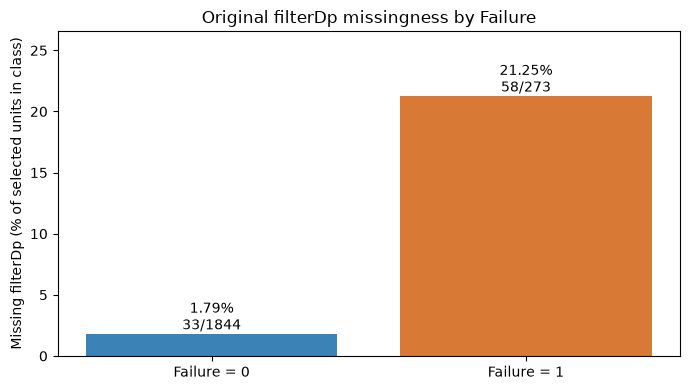

In [7]:
assert h2_data["unit_key"].is_unique
assert h2_data["Failure"].isin([0, 1]).all()
# Verify availability against the original readings, not a filled measurement.
original_filter = readings_raw.loc[h2_data["reading_row_id"], "filterDp"].reset_index(drop=True)
assert np.array_equal(h2_data["filterDp"].isna(), original_filter.isna())
assert np.array_equal(h2_data["filterDp_missing"], original_filter.isna())
missing_table = pd.crosstab(h2_data["Failure"], h2_data["filterDp_missing"]).reindex(
    index=[0, 1], columns=[False, True], fill_value=0
)
missing_table.columns = ["filterDp observed", "filterDp missing"]
assert missing_table.to_numpy().sum() == len(h2_data)
print("Observed counts:")
display(missing_table)
missing_percent = 100 * missing_table["filterDp missing"] / missing_table.sum(axis=1)
display(pd.DataFrame({"units": missing_table.sum(axis=1),
    "missing_count": missing_table["filterDp missing"],
    "missing_percent": missing_percent}).round(2))

# Pearson test without Yates correction; all expected cells must be at least 5.
chi2_stat, chi2_p, chi2_df, expected = stats.chi2_contingency(
    missing_table.to_numpy(), correction=False
)
expected_table = pd.DataFrame(expected, index=missing_table.index, columns=missing_table.columns)
print("Expected counts under independence:")
display(expected_table.round(2))
assert (expected >= 5).all(), "Use an exact alternative for sparse expected counts."
print(f"Minimum expected count: {expected.min():.2f}; all four cells >= 5.")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([0, 1], missing_percent.to_numpy(), color=["#3B82B6", "#D97936"])
ax.set_xticks([0, 1], labels=["Failure = 0", "Failure = 1"])
ax.set_ylabel("Missing filterDp (% of selected units in class)")
ax.set_title("Original filterDp missingness by Failure")
ax.set_ylim(0, max(missing_percent) * 1.25)
for bar, percent, label in zip(bars, missing_percent, [0, 1]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
        f"{percent:.2f}%\n{missing_table.loc[label, 'filterDp missing']}/{missing_table.loc[label].sum()}",
        ha="center", va="bottom")
fig.tight_layout()
plt.show()

### Assumptions and test choice

Use a **Pearson chi-square independence test** (1 degree of freedom, without
Yates correction). Each unit contributes exactly one paired observation of
Failure and availability. All four expected counts exceed 5 (minimum 11.74),
so the large-sample approximation is suitable; Fisher's exact test is not needed
for sparse cells here. Independence across different units is still assumed.
A chi-square test on all repeated measurement rows would violate this design.

Report the odds ratio as the odds of missing filterDp in Failure = 1 divided by
the odds in Failure = 0. The equivalent cross-product ratio also describes the
odds of Failure for missing versus observed filterDp. A value of 1 indicates
no odds association. Use a 95% interval on the log-odds scale; no zero-cell
correction is necessary. Cramer's V gives an additional unsigned association
measure. Neither the odds ratio nor V is a causal effect.

In [8]:
observed0, missing0 = missing_table.loc[0].to_numpy()
observed1, missing1 = missing_table.loc[1].to_numpy()
assert min(observed0, missing0, observed1, missing1) > 0
odds_ratio = (missing1 * observed0) / (observed1 * missing0)
log_or_se = np.sqrt(1/missing1 + 1/observed1 + 1/missing0 + 1/observed0)
odds_ratio_ci = np.exp(np.log(odds_ratio) + np.array([-1, 1]) * stats.norm.ppf(0.975) * log_or_se)
cramers_v = np.sqrt(chi2_stat / missing_table.to_numpy().sum())
display(pd.DataFrame([{
    "test": "Pearson chi-square", "chi2": chi2_stat, "df": chi2_df,
    "p_value": chi2_p, "alpha": ALPHA, "odds_ratio": odds_ratio,
    "OR_95CI_lower": odds_ratio_ci[0], "OR_95CI_upper": odds_ratio_ci[1],
    "Cramers_V": cramers_v,
}]))
display(Markdown(
    f"**Interpretation:** chi-square({chi2_df}) = {chi2_stat:.3f}, "
    f"p = {chi2_p:.3g}. At alpha = {ALPHA}, "
    f"{'reject' if chi2_p < ALPHA else 'do not reject'} H0. "
    f"Missingness is {missing_percent.loc[1]:.2f}% in Failure = 1 versus "
    f"{missing_percent.loc[0]:.2f}% in Failure = 0. "
    f"The estimated odds of missing filterDp are {odds_ratio:.2f} times as high "
    f"in the failure-labelled group (95% CI {odds_ratio_ci[0]:.2f} to "
    f"{odds_ratio_ci[1]:.2f}); Cramer's V = {cramers_v:.3f}. "
    f"The odds ratio is not a ratio of probabilities. "
    f"The observed percentage difference and effect sizes describe the association; "
    f"its operational usefulness cannot be inferred from significance alone."
))

# Holm adjustment for the two primary research tests, excluding diagnostics.
primary_results = pd.DataFrame({
    "hypothesis": ["H1: serviceHours", "H2: filterDp missingness"],
    "p_value": [h1_result.pvalue, chi2_p],
}).sort_values("p_value")
primary_results["Holm_adjusted_p"] = np.minimum(
    1, np.maximum.accumulate(primary_results["p_value"].to_numpy() * np.array([2, 1]))
)
primary_results["reject_at_family_alpha_0.05"] = primary_results["Holm_adjusted_p"] < ALPHA
print("Two primary hypotheses: Holm family-wise adjustment")
display(primary_results.sort_index().reset_index(drop=True))

,test,chi2,df,p_value,alpha,odds_ratio,OR_95CI_lower,OR_95CI_upper,Cramers_V
0,Pearson chi-square,218.808035,1,1.645829e-49,0.05,14.80451,9.438427,23.221404,0.321493


**Interpretation:** chi-square(1) = 218.808, p = 1.65e-49. At alpha = 0.05, reject H0. Missingness is 21.25% in Failure = 1 versus 1.79% in Failure = 0. The estimated odds of missing filterDp are 14.80 times as high in the failure-labelled group (95% CI 9.44 to 23.22); Cramer's V = 0.321. The odds ratio is not a ratio of probabilities. The observed percentage difference and effect sizes describe the association; its operational usefulness cannot be inferred from significance alone.

Two primary hypotheses: Holm family-wise adjustment


,hypothesis,p_value,Holm_adjusted_p,reject_at_family_alpha_0.05
0,H1: serviceHours,1.243805e-11,1.243805e-11,True
1,H2: filterDp missingness,1.645829e-49,3.291658e-49,True


The association could reflect sensor reporting, operational conditions or failure
recording procedures. The data do not establish whether missingness occurred
before or after Failure. Missingness is retained as information, but predictive
use would require a timing check. No imputation or new cleaning is performed.

Both primary comparisons remain significant after Holm adjustment for two tests
at family alpha = 0.05. The displayed 95% effect intervals are individual intervals,
not simultaneous family-wise intervals. Diagnostic p-values were not treated as
additional research claims. These exploratory results remain conditional on the
fixed sampled occasion, complete cases for H1, and independence across units.
One row per unit avoids within-unit replication but discards longitudinal detail;
shared depot or maintenance conditions may still cause dependence. Statistical
power is assessed separately in Section 5; significance alone does not establish adequate power.

## 5. Statistical Power Analysis

### Definitions and planning assumptions

**Alpha = 0.05** is the probability of a Type I error (rejecting a true null),
subject to test assumptions. A **Type II error** is failing to reject the null
when a specified alternative is true. Its probability is beta; **power = 1 - beta**.
Our target is **0.80**. Power depends on the alternative effect, sample size,
allocation and test, so it is not a single property of this dataset.

Use the independent-unit samples already tested: H1 has 1,648 non-failure and
250 failure units; H2 has 1,844 and 273. Report allocation as n1/n0. Do not use
13,092 correlated sensor rows as the sample size. Future sample-size scenarios
retain each comparison's observed allocation, with integer rounding. H1 sizes
refer to units with available service hours, not the number to recruit before
missing metadata; H2 retains missing filterDp as an outcome.

We show per-test alpha = 0.05 and alpha = 0.025. The latter is a conservative
threshold sufficient for rejection by Holm when testing two hypotheses at family
alpha = 0.05. It does not reproduce Holm's adaptive joint power and does not
promise an 80% probability of detecting both effects together.

No minimum important effect has been supplied by an equipment expert. The
following **illustrative practical benchmarks are planning assumptions**, chosen
before these power simulations, not measured effects or validated thresholds:

- H1: probability of superiority **A = 0.60**, or rank-biserial effect **0.20**.
  This represents a ten-percentage-point pairwise advantage above chance.
- H2: missingness **p0 = 0.02 versus p1 = 0.07**, an absolute difference of
  **5 percentage points**. A 2% baseline is a rounded planning assumption,
  informed by the non-failure missingness rate, not an independent estimate.
  The five-point increase represents an illustrative deterioration in reporting.

We evaluate these assumptions and find the smallest effect on a stated grid
supported at 80% power. We do not calculate power from the observed effect and
then use it to validate the test. Such post-hoc observed power would not provide
independent evidence of test quality.

### Simulation methods

**H1:** Simulate independent lognormal service-hour values, with the same shape
in both groups and a shift on the log scale: X0 = exp(Z0), X1 = exp(Z1 + d),
where Z0 and Z1 are standard normal and d = sqrt(2) * Phi-inverse(A).
This gives the chosen pairwise superiority A exactly in the population. Scaling
both groups into hours would not change their ranks. Apply the same two-sided,
asymptotic Mann-Whitney test with continuity correction as in Section 3.
This is an illustrative continuous shift model, not a fitted description of the
observed unequal spreads. Power is not determined by A alone for arbitrary
shapes; results need not apply to all alternatives or actual rounded-value ties.

**H2:** Simulate independent missingness indicators conditional on the two fixed
Failure group sizes: counts follow Binomial(n0, p0) and Binomial(n1, p1).
Compute the same uncorrected Pearson statistic and chi-square(1) p-value used in
Section 4. This directly simulates the selected test rather than applying a
t-test power formula or treating an odds ratio as Cohen's w. The assumed effect
is a rate difference; also show its odds ratio and Cohen's w for the planned
2-by-2 probabilities. Here w equals population Cramer's V, and it depends on
allocation and baseline missingness as well as the rate difference.

The code uses 2,000 simulations per H1 scenario and 20,000 per H2 scenario,
with fixed random seeds. Monte Carlo standard errors and 95% Wilson intervals
quantify simulation uncertainty. A null scenario checks rejection rates against
the nominal alpha; it cannot prove calibration under every data-generating model.
Sparse simulated H2 tables are reported, never silently discarded. Large-sample
chi-square calibration is a limitation when rates or samples are small.

Effects are searched on grids (H1 A in steps of 0.01; H2 rate increases in steps
of 0.005). A conservative grid threshold requires the **lower simulation interval
bound** to reach 0.80. This is a grid-based sensitivity estimate, not an exact
mathematical minimum. Required sample sizes use a separate labelled grid and
also require planned expected H2 cells to be at least 5. No resampling choice
or original hypothesis-test result is changed.

Implementation reference: [SciPy Mann-Whitney documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.mannwhitneyu.html)
for the two-sided asymptotic test and continuity correction.

In [9]:
TARGET_POWER = 0.80
POWER_ALPHAS = (ALPHA, ALPHA / 2)
MW_REPETITIONS = 2000
CHI_REPETITIONS = 20000
ASSUMED_A = 0.60
ASSUMED_P0 = 0.02
ASSUMED_RATE_INCREASE = 0.05

n0_h1, n1_h1 = len(service_groups[0]), len(service_groups[1])
h2_sizes = h2_data.groupby("Failure").size()
n0_h2, n1_h2 = int(h2_sizes.loc[0]), int(h2_sizes.loc[1])
assert n0_h1 + n1_h1 == len(h1_data) == h1_data["unit_key"].nunique()
assert n0_h2 + n1_h2 == len(h2_data) == h2_data["unit_key"].nunique()
allocations = pd.DataFrame([
    {"hypothesis": "H1", "n0": n0_h1, "n1": n1_h1},
    {"hypothesis": "H2", "n0": n0_h2, "n1": n1_h2},
]).set_index("hypothesis")
allocations["N"] = allocations["n0"] + allocations["n1"]
allocations["allocation_n1_over_n0"] = allocations["n1"] / allocations["n0"]
display(allocations.round(4))

def rejection_summary(pvalues, alpha):
    count, repetitions = int(np.sum(pvalues < alpha)), len(pvalues)
    estimate = count / repetitions
    z = stats.norm.ppf(0.975)
    denominator = 1 + z*z / repetitions
    center = (estimate + z*z/(2*repetitions)) / denominator
    half = z * np.sqrt(estimate*(1-estimate)/repetitions + z*z/(4*repetitions**2)) / denominator
    return {"power": estimate, "MC_SE": np.sqrt(estimate*(1-estimate)/repetitions),
            "MC_95_low": max(0, center-half), "MC_95_high": min(1, center+half)}

def simulate_mw(n0, n1, a, seed):
    rng = np.random.default_rng(seed)
    shift = np.sqrt(2) * stats.norm.ppf(a)
    pvalues = np.empty(MW_REPETITIONS)
    # Batches keep memory use small; observations represent different units.
    for first in range(0, MW_REPETITIONS, 100):
        size = min(100, MW_REPETITIONS-first)
        group0 = np.exp(rng.normal(size=(size, n0)))
        group1 = np.exp(rng.normal(size=(size, n1)) + shift)
        pvalues[first:first+size] = stats.mannwhitneyu(
            group1, group0, axis=1, alternative="two-sided",
            method="asymptotic", use_continuity=True,
        ).pvalue
    return [{"alpha": alpha, **rejection_summary(pvalues, alpha)} for alpha in POWER_ALPHAS]

def planned_binary_effect(n0, n1, p0, p1):
    allocation = np.array([n0, n1]) / (n0+n1)
    joint = allocation[:, None] * np.array([[1-p0, p0], [1-p1, p1]])
    independent = np.outer(allocation, joint.sum(axis=0))
    w = np.sqrt(np.sum((joint-independent)**2 / independent))
    odds = (p1/(1-p1)) / (p0/(1-p0))
    return w, odds, float(((n0+n1)*independent).min())

def simulate_chi(n0, n1, p0, p1, seed):
    rng = np.random.default_rng(seed)
    missing0 = rng.binomial(n0, p0, size=CHI_REPETITIONS)
    missing1 = rng.binomial(n1, p1, size=CHI_REPETITIONS)
    missing_total = missing0 + missing1
    total = n0+n1
    denominator = n0 * n1 * missing_total.astype(float) * (total-missing_total)
    numerator = total * (missing1*n0 - missing0*n1).astype(float)**2
    # An all-observed/all-missing table contains no availability contrast.
    chi_stat = np.divide(numerator, denominator, out=np.zeros(CHI_REPETITIONS), where=denominator>0)
    pvalues = stats.chi2.sf(chi_stat, df=1)
    expected_min = np.minimum(n0, n1) * np.minimum(missing_total, total-missing_total) / total
    w, odds, planned_min = planned_binary_effect(n0, n1, p0, p1)
    return [{"alpha": alpha, **rejection_summary(pvalues, alpha),
             "Cohen_w": w, "assumed_OR": odds, "planned_min_expected": planned_min,
             "simulated_sparse_percent": 100*np.mean(expected_min < 5)}
            for alpha in POWER_ALPHAS]

# Algebra check: the vectorized statistic matches the original Pearson test.
check_counts = missing_table.to_numpy()
a0, b0 = check_counts[0]
a1, b1 = check_counts[1]
check_stat = check_counts.sum() * float(b1*a0-b0*a1)**2 / (
    (a0+b0)*(a1+b1)*(b0+b1)*(a0+a1)
)
assert np.isclose(check_stat, chi2_stat)

mw_effect_rows = []
for i, a in enumerate(np.round(np.arange(0.50, 0.651, 0.01), 2)):
    for result in simulate_mw(n0_h1, n1_h1, a, seed=5100+i):
        mw_effect_rows.append({"A": a, "rank_biserial": 2*a-1, **result})
mw_sensitivity = pd.DataFrame(mw_effect_rows)
chi_effect_rows = []
for i, increase in enumerate(np.round(np.arange(0, 0.0801, 0.005), 3)):
    for result in simulate_chi(n0_h2, n1_h2, ASSUMED_P0, ASSUMED_P0+increase, seed=5200+i):
        chi_effect_rows.append({"rate_increase": increase, "p0": ASSUMED_P0,
                                "p1": ASSUMED_P0+increase, **result})
chi_sensitivity = pd.DataFrame(chi_effect_rows)
print("Null calibration: rejection probability should be near the stated alpha.")
display(pd.concat([
    mw_sensitivity.loc[mw_sensitivity["A"].eq(0.5)].assign(test="Mann-Whitney"),
    chi_sensitivity.loc[chi_sensitivity["rate_increase"].eq(0)].assign(test="Pearson chi-square"),
], ignore_index=True)[["test", "alpha", "power", "MC_SE", "MC_95_low", "MC_95_high"]])

,n0,n1,N,allocation_n1_over_n0
hypothesis,,,,
H1,1648,250,1898,0.1517
H2,1844,273,2117,0.1480


Null calibration: rejection probability should be near the stated alpha.


,test,alpha,power,MC_SE,MC_95_low,MC_95_high
0,Mann-Whitney,0.050,0.0460,0.004684,0.037657,0.056084
1,Mann-Whitney,0.025,0.0230,0.003352,0.017288,0.030541
2,Pearson chi-square,0.050,0.0498,0.001538,0.046871,0.052902
3,Pearson chi-square,0.025,0.0257,0.001119,0.023596,0.027986


Summary: H1 effects are A; H2 effects are absolute missingness-rate increases.


,hypothesis,alpha,N available,Detectable effect (grid),Benchmark power (95% MC interval),N required (grid),Sufficient for assumed effect
0,H1,0.050,1898,0.560,1.000 (0.997-1.000),750,True
1,H2,0.050,2117,0.035,0.978 (0.976-0.980),1500,True
2,H1,0.025,1898,0.570,0.998 (0.995-0.999),750,True
3,H2,0.025,2117,0.035,0.966 (0.963-0.968),1500,True


H2 assumed effect and sparse-table diagnostic at available N:


,alpha,p0,p1,assumed_OR,Cohen_w,planned_min_expected,simulated_sparse_percent
20,0.050,0.02,0.07,3.6882,0.1044,7.2203,0.62
21,0.025,0.02,0.07,3.6882,0.1044,7.2203,0.62


Independent sample-size grids evaluated (minimum adequate grid point, not exact minimum):
H1: [500, 750, 1000, 1250, 1500, 1750, 1898, 2250, 2500, 3000]
H2: [500, 750, 1000, 1250, 1500, 1750, 2000, 2117, 2500, 3000, 4000]


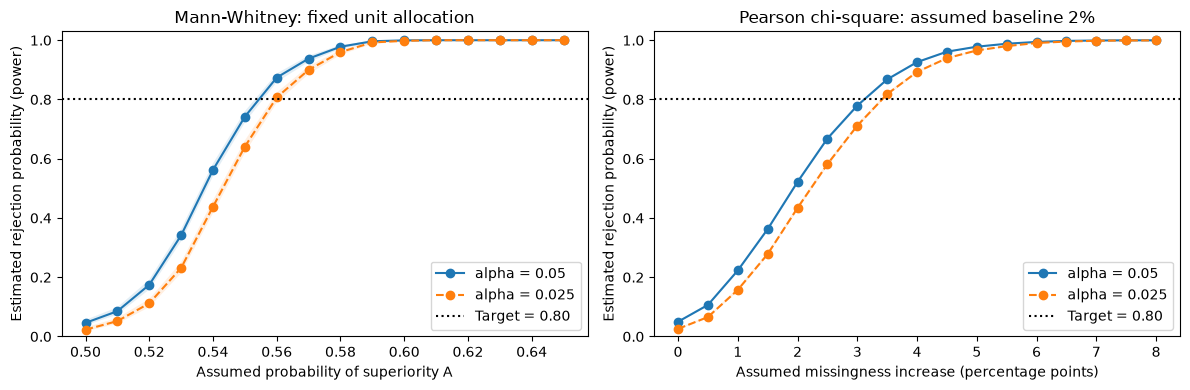

In [10]:
def allocated_counts(total, n0, n1):
    new_n1 = int(round(total*n1/(n0+n1)))
    return total-new_n1, new_n1

mw_size_rows, chi_size_rows = [], []
# These are planned independent, analysable unit counts, not sensor row counts.
mw_size_grid = sorted(set([500, 750, 1000, 1250, 1500, 1750, len(h1_data), 2250, 2500, 3000]))
chi_size_grid = sorted(set([500, 750, 1000, 1250, 1500, 1750, 2000, len(h2_data), 2500, 3000, 4000]))
for i, total in enumerate(mw_size_grid):
    new_n0, new_n1 = allocated_counts(total, n0_h1, n1_h1)
    # Reuse the existing simulation at the available N.
    results = (mw_sensitivity.loc[np.isclose(mw_sensitivity["A"], ASSUMED_A)].to_dict("records")
               if total == len(h1_data) else simulate_mw(new_n0, new_n1, ASSUMED_A, 5300+i))
    for result in results:
        mw_size_rows.append({**result, "N": total, "n0": new_n0, "n1": new_n1})
for i, total in enumerate(chi_size_grid):
    new_n0, new_n1 = allocated_counts(total, n0_h2, n1_h2)
    results = (chi_sensitivity.loc[np.isclose(chi_sensitivity["rate_increase"], ASSUMED_RATE_INCREASE)].to_dict("records")
               if total == len(h2_data) else simulate_chi(
                   new_n0, new_n1, ASSUMED_P0, ASSUMED_P0+ASSUMED_RATE_INCREASE, 5400+i))
    for result in results:
        chi_size_rows.append({**result, "N": total, "n0": new_n0, "n1": new_n1})
mw_sample_planning = pd.DataFrame(mw_size_rows)
chi_sample_planning = pd.DataFrame(chi_size_rows)

summary_rows = []
for alpha in POWER_ALPHAS:
    mw_effects = mw_sensitivity.loc[mw_sensitivity["alpha"].eq(alpha)]
    chi_effects = chi_sensitivity.loc[chi_sensitivity["alpha"].eq(alpha)]
    minimum_a = mw_effects.loc[mw_effects["MC_95_low"].ge(TARGET_POWER)].iloc[0]
    minimum_increase = chi_effects.loc[
        chi_effects["MC_95_low"].ge(TARGET_POWER) & chi_effects["planned_min_expected"].ge(5)
    ].iloc[0]
    for hypothesis, effects, planning, benchmark, minimum, effect_column, available, n0, n1 in [
        ("H1", mw_effects, mw_sample_planning, ASSUMED_A, minimum_a, "A", len(h1_data), n0_h1, n1_h1),
        ("H2", chi_effects, chi_sample_planning, ASSUMED_RATE_INCREASE, minimum_increase,
         "rate_increase", len(h2_data), n0_h2, n1_h2),
    ]:
        at_benchmark = effects.loc[np.isclose(effects[effect_column], benchmark)].iloc[0]
        candidates = planning.loc[planning["alpha"].eq(alpha) & planning["MC_95_low"].ge(TARGET_POWER)]
        if hypothesis == "H2":
            candidates = candidates.loc[candidates["planned_min_expected"].ge(5)]
        required = candidates.sort_values("N").iloc[0]
        summary_rows.append({
            "hypothesis": hypothesis, "alpha": alpha, "target_power": TARGET_POWER,
            "available_N": available, "n0": n0, "n1": n1, "n1/n0": n1/n0,
            "assumed_benchmark": benchmark, "grid_detectable_effect": minimum[effect_column],
            "benchmark_power": at_benchmark["power"],
            "power_MC95_low": at_benchmark["MC_95_low"], "power_MC95_high": at_benchmark["MC_95_high"],
            "required_N_on_grid": int(required["N"]),
            "required_n0": int(required["n0"]), "required_n1": int(required["n1"]),
            "sufficient_for_assumed_effect": bool(at_benchmark["MC_95_low"] >= TARGET_POWER),
        })
power_summary = pd.DataFrame(summary_rows)
print("Summary: H1 effects are A; H2 effects are absolute missingness-rate increases.")
compact_power_summary = power_summary[[
    "hypothesis", "alpha", "available_N", "grid_detectable_effect",
    "benchmark_power", "required_N_on_grid", "sufficient_for_assumed_effect",
]].copy()
compact_power_summary["benchmark_power"] = [
    f"{r.benchmark_power:.3f} ({r.power_MC95_low:.3f}-{r.power_MC95_high:.3f})"
    for r in power_summary.itertuples()
]
compact_power_summary = compact_power_summary.rename(columns={
    "available_N": "N available", "grid_detectable_effect": "Detectable effect (grid)",
    "benchmark_power": "Benchmark power (95% MC interval)",
    "required_N_on_grid": "N required (grid)",
    "sufficient_for_assumed_effect": "Sufficient for assumed effect",
})
display(compact_power_summary)
print("H2 assumed effect and sparse-table diagnostic at available N:")
display(chi_sensitivity.loc[np.isclose(chi_sensitivity["rate_increase"], ASSUMED_RATE_INCREASE),
    ["alpha", "p0", "p1", "assumed_OR", "Cohen_w", "planned_min_expected", "simulated_sparse_percent"]].round(4))
print("Independent sample-size grids evaluated (minimum adequate grid point, not exact minimum):")
print("H1:", mw_size_grid)
print("H2:", chi_size_grid)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for alpha, style in zip(POWER_ALPHAS, ("-", "--")):
    for ax, table, effect, multiplier in [
        (axes[0], mw_sensitivity, "A", 1),
        (axes[1], chi_sensitivity, "rate_increase", 100),
    ]:
        rows = table.loc[table["alpha"].eq(alpha)]
        grid = multiplier*rows[effect].to_numpy()
        ax.plot(grid, rows["power"], style, marker="o", label=f"alpha = {alpha}")
        ax.fill_between(grid, rows["MC_95_low"], rows["MC_95_high"], alpha=0.12)
for ax in axes:
    ax.axhline(TARGET_POWER, color="black", linestyle=":", label="Target = 0.80")
    ax.set_ylabel("Estimated rejection probability (power)")
    ax.set_ylim(0, 1.03)
    ax.legend()
axes[0].set(title="Mann-Whitney: fixed unit allocation", xlabel="Assumed probability of superiority A")
axes[1].set(title="Pearson chi-square: assumed baseline 2%", xlabel="Assumed missingness increase (percentage points)")
fig.tight_layout()
plt.show()

In [11]:
for hypothesis in ("H1", "H2"):
    row = power_summary.loc[power_summary["hypothesis"].eq(hypothesis)
                            & power_summary["alpha"].eq(ALPHA/2)].iloc[0]
    effect_description = (f"A = {row['grid_detectable_effect']:.2f} "
                          f"(rank-biserial {2*row['grid_detectable_effect']-1:.2f})"
                          if hypothesis == "H1" else
                          f"a {100*row['grid_detectable_effect']:.1f}-percentage-point increase "
                          f"from the assumed 2% baseline")
    display(Markdown(
        f"**{hypothesis}:** At the conservative alpha = 0.025, the smallest supported "
        f"effect on our grid is {effect_description}. For the illustrative benchmark, "
        f"estimated power is {row['benchmark_power']:.3f} (simulation 95% interval "
        f"{row['power_MC95_low']:.3f} to {row['power_MC95_high']:.3f}). "
        f"The available {int(row['available_N']):,} independent units "
        f"{'are sufficient' if row['sufficient_for_assumed_effect'] else 'are not sufficient'} "
        f"for this assumed effect under the simulation model. The first adequate "
        f"sample-size grid point is {int(row['required_N_on_grid']):,} analysable units "
        f"(n0 = {int(row['required_n0']):,}, n1 = {int(row['required_n1']):,})."
    ))

**H1:** At the conservative alpha = 0.025, the smallest supported effect on our grid is A = 0.57 (rank-biserial 0.14). For the illustrative benchmark, estimated power is 0.998 (simulation 95% interval 0.995 to 0.999). The available 1,898 independent units are sufficient for this assumed effect under the simulation model. The first adequate sample-size grid point is 750 analysable units (n0 = 651, n1 = 99).

**H2:** At the conservative alpha = 0.025, the smallest supported effect on our grid is a 3.5-percentage-point increase from the assumed 2% baseline. For the illustrative benchmark, estimated power is 0.966 (simulation 95% interval 0.963 to 0.968). The available 2,117 independent units are sufficient for this assumed effect under the simulation model. The first adequate sample-size grid point is 1,500 analysable units (n0 = 1,307, n1 = 193).

### Assessment and limitations

The summary and curves evaluate power separately for both actual tests, using
independent-unit counts and observed class imbalance. They meet requirement
1.3(B) by comparing available samples, simulated detectable effects and sample
sizes for explicit planning alternatives against a target of 0.80. Whether these
benchmarks are practically important must be confirmed by domain experts; we
cannot declare the data sufficient for every practically relevant effect.
Smaller effects may have inadequate power despite the significant observed tests.

The results are conditional on the one-selected-occasion design, independent
units and the simulated distributions. They do not address shared-depot dependence,
uncertainty in group allocation, selection of a different occasion, informative
missing service hours, or uncertain metadata timing. H1's equal-shape simulation
is a sensitivity scenario despite the unequal observed spreads. H2 depends on
the assumed baseline rate and the large-sample Pearson reference distribution;
sparse simulated tables are included and their frequency reported. Null rejection
rates and simulation intervals help assess numerical reliability, not all these
substantive assumptions. No model training or changes to the hypothesis tests
were made.

## 6. Conclusions

The two research comparisons use one fixed, randomly selected reading per unit.
This avoids treating repeated readings as independent. Both associations remain
significant after Holm adjustment for the two tests at family alpha = 0.05.

- **Service hours:** Among 1,898 units with available values, the two-sided
  Mann-Whitney test gives U = 260,706 and p = 1.24e-11. Failure-labelled units
  tend to have higher service hours: A = 0.633 (95% bootstrap interval
  0.598-0.669), with rank-biserial effect 0.266. The distributions overlap;
  this is not a test solely of median differences.
- **Missing filterDp:** Among 2,117 units, missingness is 21.25% in Failure = 1
  versus 1.79% in Failure = 0. Pearson chi-square(1) = 218.808, p = 1.65e-49.
  The missingness odds ratio is 14.80 (95% CI 9.44-23.22), with Cramer's
  V = 0.321. Missingness may reflect the reporting or failure-recording process.
- **Power:** At conservative alpha = 0.025, simulated power exceeds 0.80 for
  the assumed benchmarks: 0.998 for A = 0.60 and 0.966 for a missingness
  increase from 2% to 7%. The supported sensitivity-grid thresholds are
  A = 0.57 and a 3.5-percentage-point increase, respectively. These results
  depend on the simulation models and illustrative benchmarks, not a
  domain-validated minimum important effect.

These results support further investigation of serviceHours and original
filterDp availability as potential predictors. Before later ML phases, verify
that both are available before the prediction time and define the failure
prediction horizon. Split and evaluate data by unit, with time ordering where
reliable, so repeated readings do not leak across training and evaluation.
Fit any imputation or preprocessing on training data only, and assess predictive
usefulness on held-out data rather than selecting features from p-values alone.
No model or preprocessing pipeline is implemented here.

The findings are exploratory and do not establish causality or advance prediction.
One reading per unit loses longitudinal information; different units may still
share depot or maintenance conditions. Missing service hours, unresolved dates
and uncertain metadata timing remain limitations. Power for smaller effects or
different distribution shapes may be lower.


## 7. Contributions

- Dmytro Petrenko: **[fill in actual percentage]%** - [describe actual work].
- Oleh Serdiukov: **[fill in actual percentage]%** - [describe actual work].

The authors must complete these fields before submission. Percentages should
reflect the work on this phase and sum to 100%.
